# 15.1. Hückel 근사

In [1]:
import numpy as np


def huckel(n_carbons, bonds, alpha=0.0, beta=-1.0):
    H = alpha * np.eye(n_carbons)
    for i, j in bonds:
        H[i, j] = beta
        H[j, i] = beta
    E, C = np.linalg.eigh(H)
    return E, C


E, C = huckel(2, [(0, 1)])
print("에틸렌의 에너지 계수:", -E)

E, C = huckel(4, [(0, 1), (1, 2), (2, 3)])
print("부타디엔의 에너지 계수:", np.round(-E, 3))

에틸렌의 에너지 계수: [ 1. -1.]
부타디엔의 에너지 계수: [ 1.618  0.618 -0.618 -1.618]


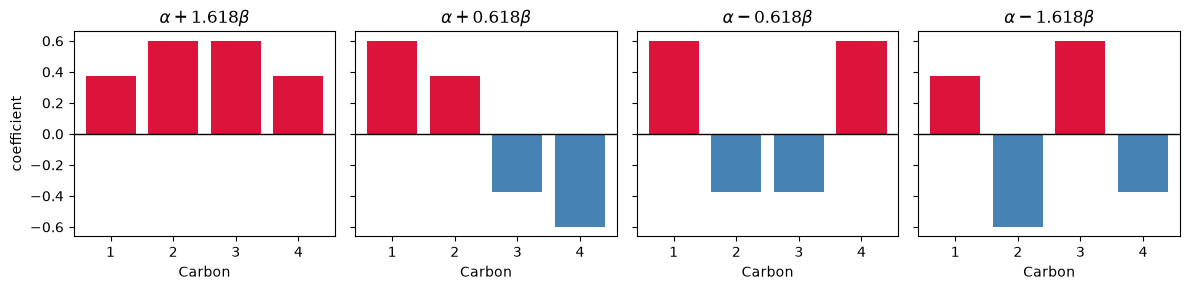

In [2]:
import matplotlib.pyplot as plt

C = C * np.sign(C[0])

fig, axes = plt.subplots(1, 4, figsize=(12, 3), sharey=True)
for k, ax in enumerate(axes):
    colors = ["crimson" if c > 0 else "steelblue" for c in C[:, k]]
    ax.bar(range(1, 5), C[:, k], color=colors)
    ax.axhline(0, color="black", lw=1)
    ax.set_xticks(range(1, 5))
    ax.set_title(rf"$\alpha {-E[k]:+.3f}\beta$", fontsize=12)
    ax.set_xlabel("Carbon")
axes[0].set_ylabel("coefficient")
plt.tight_layout()
plt.show()

In [3]:
def pi_bonds(C, n_electrons):
    occ = np.zeros(C.shape[1])
    occ[: (n_electrons // 2)] = 2
    occ[n_electrons // 2] += n_electrons % 2
    q = (C**2) @ occ
    p = (C * occ) @ C.T
    return q, p


q, p = pi_bonds(C, 4)
print("pi 전자 밀도:", np.round(q, 3))
print("pi 결합 차수:", np.round(p[0, 1], 3), np.round(p[1, 2], 3), np.round(p[2, 3], 3))

pi 전자 밀도: [1. 1. 1. 1.]
pi 결합 차수: 0.894 0.447 0.894
